In [1]:
import numpyro
import numpyro.distributions as dist
import arviz as az

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx
# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

4

In [2]:
def deact_ODE(t, y, params):
  print(params)
  k_deact, Ea_deact, n_deact, T = params
  R = 8.314
  T_ref= 550
  k = jnp.expand_dims(k_deact * jnp.exp(Ea_deact / R * (1.0 / T_ref - 1.0 / T)), -2)
  dy = jnp.where(
      y <= 1e-3,
      0.0,
      -k * y**n_deact,
  )
  return dy


In [3]:
def kinetics_model(p_i, T, k0, Ea_k, k_deact, Ea_deact, n_deact):
  n_obs = T.shape[0]

  R = 8.314
  T_ref= 550.0
  # Arrhenius rate constant
  k = k0 * jnp.exp(Ea_k / R * (1.0 / T_ref - 1.0 / T))

  # Van't Hoff adsorption equilibrium constants
  K_OH = 0.5 * jnp.exp(22.4e3 / R * (1.0 / T_ref - 1.0 / T))
  K_H2 = 0.44 * jnp.exp(-6.2e3 / R * (1.0 / T_ref - 1.0 / T))
  K_mix = 0.88 * jnp.exp(-10.0e3 / R * (1.0 / T_ref - 1.0 / T))

  # Thermodynamic equilibrium constant for CO2 methanation
  K_eq = 137.0 * T ** (-4.0) * jnp.exp(158700.0 / (R * T))

  # Extract partial pressures (indexed directly for JIT optimization)
  p_CO2 = p_i[:, 0, None]  # SIDX["CO2"] = 0
  p_H2 = p_i[:, 1, None]  # SIDX["H2"] = 1
  p_H2O = p_i[:, 2, None]  # SIDX["H2O"] = 2
  p_CH4 = p_i[:, 3, None]  # SIDX["CH4"] = 3

  # Reaction driving force (1 - Q/K_eq)
  driving_force = 1.0 - (p_CH4 * p_H2O**2.0) / (p_CO2 * p_H2**4.0 * K_eq)

  # Denominator: adsorption inhibition term (squared LHHW form)
  sqrt_p_H2 = jnp.sqrt(p_H2)
  sqrt_p_CO2 = jnp.sqrt(p_CO2)

  inhibition = (
      1.0 + (K_OH * p_H2O) / sqrt_p_H2 + K_H2 * sqrt_p_H2 + K_mix * sqrt_p_CO2
  ) ** 2.0

  # LHHW rate equation
  r = k * sqrt_p_H2 * sqrt_p_CO2 * driving_force / inhibition
  r = jnp.expand_dims(r, -2)
  n_draws = r.shape[2]

  ode_term = dfx.ODETerm(deact_ODE)
  solver = dfx.Tsit5()

  stepsize_controller = dfx.PIDController(rtol=1e-8, atol=1e-12)

  a0 = jnp.ones((n_obs,1,n_draws))
  # Solve the ODE system
  solution = dfx.diffeqsolve(
      ode_term,
      solver,
      t0=0.0,
      t1=60.0,
      dt0=None,  # Let Diffrax choose initial step size
      y0=a0,
      args=(k_deact, Ea_deact, n_deact, T),
      saveat=dfx.SaveAt(ts=jnp.linspace(0.0,60.0,10)),
      stepsize_controller=stepsize_controller,
      #max_steps=2**20,
  )

  a = solution.ys

  return a*r

In [4]:
def calculate_partial_pressures(
    p_total,
    c2h_ratio,
    c2m_ratio,
    c2w_ratio,
    c2i_ratio,
):
    """
    Calculate partial pressures from total pressure and molar ratios.

    Args:
        p_total: Total pressure array of shape (n_conditions, 1) [bar]
        c2h_ratio: CO2/H2 molar ratio array of shape (n_conditions, 1) [-]
        feed_ratio: Feed dilution ratio (CO2+H2)/CH4 of shape (n_conditions, 1) [-]
        c2i_ratio: CO2/Inert molar ratio array of shape (n_conditions, 1) [-]

    Returns:
        Partial pressure array of shape (n_conditions, 5) [bar]
    """
    # Convert to tensors if needed
    # p_total = torch.as_tensor(p_total, dtype=torch.float32)
    # c2h_ratio = torch.as_tensor(c2h_ratio, dtype=torch.float32)
    # feed_ratio = torch.as_tensor(feed_ratio, dtype=torch.float32)
    # c2i_ratio = torch.as_tensor(c2i_ratio, dtype=torch.float32)

    # Calculate CO2 mole fraction from ratios
    x_co2 = (1 / (1 + 1 / c2h_ratio + 1 / c2m_ratio + 1 / c2w_ratio + 1 / c2i_ratio)).squeeze(-1)

    # Calculate other species mole fractions
    x_h2 = x_co2 / c2h_ratio.squeeze(-1)
    x_m = x_co2 / c2m_ratio.squeeze(-1)
    x_w = x_co2 / c2w_ratio.squeeze(-1)
    x_i = x_co2 / c2i_ratio.squeeze(-1)

    xi = jnp.stack(
        (x_co2, x_h2, x_w, x_m, x_i), axis=1)

    # Convert to partial pressures: p_i = x_i * p_total
    p_i = p_total * xi
    return p_i

In [ ]:
TRUE_PARAMS = {
    "k0": jnp.array(3.46e-4),  # Pre-exponential factor [mol/(bar·s·g_cat)]
    "EA": jnp.array(77.5e3),  # Activation energy [J/mol]
    "k_deact": jnp.array(1e-2),  # Deactivation rate constant [1/s]
    "EA_deact": jnp.array(75.0e3),  # Deactivation activation energy [J/mol]
    "n_deact": jnp.array(2),  # Deactivation order [-]
}
def generate_synthetic_data(
    T,
    p,
    c2h,
    c2m,
    c2w,
    c2i,
    rel_noise_std: float = 0.05,
    seed = None,
):
    """
    Generate synthetic observation data using true parameters.

    Args:
        T: Temperature array [K]
        p: Total pressure array [bar]
        c2h: CO2/H2 ratio array [-]
        f: Feed ratio array [-]
        c2i: CO2/Inert ratio array [-]
        noise_std: Standard deviation of Gaussian noise
        seed: Random seed for reproducibility

    Returns:
        Tuple of (T, p_i, r_obs) ready for inference
    """
    # Set random seed
    if seed is not None:
      key=jax.random.key(seed)
    else:
      key=jax.random.key(763789678968)
      key,_ = jax.random.split(key)

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Compute true reaction rates
    r_true = kinetics_model(p_i, T, *TRUE_PARAMS.values())

    # Add Gaussian noise
    rng = jax.random.normal(key, r_true.shape)
    noise = rng * rel_noise_std * jnp.absolute(r_true)
    r_obs = r_true + noise

    return T, p_i, r_obs

In [6]:
from scipy.stats import qmc
T_range = jnp.array([450, 600])
p_range = jnp.array([3, 9])
c2h_range = jnp.array([0.2, 4])
c2m_range = jnp.array([0.5, 1000])
c2w_range = jnp.array([0.5, 1000])
c2i_range = jnp.array([0.05, 1])

n_obs = 98
sampler = qmc.LatinHypercube(d=6)
sample = sampler.random(n=n_obs)

# Scale samples to the appropriate ranges
T_lhs = qmc.scale(sample[:, 0:1], T_range[0], T_range[1])
p_lhs = qmc.scale(sample[:, 1:2], p_range[0], p_range[1])
c2h_lhs = qmc.scale(sample[:, 2:3], c2h_range[0], c2h_range[1])
c2m_lhs = qmc.scale(sample[:, 3:4], c2m_range[0], c2m_range[1])
c2w_lhs = qmc.scale(sample[:, 4:5], c2w_range[0], c2w_range[1])
c2i_lhs = qmc.scale(sample[:, 5:6], c2i_range[0], c2i_range[1])

proposals = jnp.column_stack([T_lhs, p_lhs, c2h_lhs, c2m_lhs, c2w_lhs, c2i_lhs])
print(proposals.shape)

(98, 6)


In [7]:
Ts = proposals[0, 0].reshape(-1, 1)
ps = proposals[0, 1].reshape(-1, 1)
c2hs = proposals[0, 2].reshape(-1, 1)
c2ms = proposals[0, 3].reshape(-1, 1)
c2ws = proposals[0, 4].reshape(-1, 1)
c2is = proposals[0, 5].reshape(-1, 1)
print(Ts.shape)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

display(pi.shape)

(1, 1)


(1, 5)

In [8]:
Ts = proposals[:, 0].reshape(-1, 1)
ps = proposals[:, 1].reshape(-1, 1)
c2hs = proposals[:, 2].reshape(-1, 1)
c2ms = proposals[:, 3].reshape(-1, 1)
c2ws = proposals[:, 4].reshape(-1, 1)
c2is = proposals[:, 5].reshape(-1, 1)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

display(pi.shape)

(98, 5)

In [9]:
T_obs, pi_obs, r_obs = generate_synthetic_data(Ts, ps, c2hs, c2ms, c2ws, c2is, 0.01)
print(T_obs.shape)
print(r_obs.shape)

(JitTracer<~float32[]>, JitTracer<~float32[]>, JitTracer<~int32[]>, JitTracer<float32[98,1]>)
(JitTracer<~float32[]>, JitTracer<~float32[]>, JitTracer<~int32[]>, JitTracer<float32[98,1]>)
(JitTracer<~float32[]>, JitTracer<~float32[]>, JitTracer<~int32[]>, JitTracer<float32[98,1]>)
(98, 1)
(10, 98, 1, 1)


In [10]:
def bayesian_model(T, pi, r_obs=None):
  t_k0 = jnp.expand_dims(numpyro.sample("t_k0", dist.Normal(0, 1)),0)
  t_Ea_k = jnp.expand_dims(numpyro.sample("t_Ea_k", dist.Normal(0, 0.1)),0)
  t_k_deact = jnp.expand_dims(numpyro.sample("t_k_deact", dist.Normal(0, 1)),0)
  t_Ea_deact = jnp.expand_dims(numpyro.sample("t_Ea_deact", dist.Normal(0, 0.1)),0)

  k0 = numpyro.deterministic("k0", 1e-4*jnp.exp(t_k0))
  Ea_k = numpyro.deterministic("Ea_k", 50e3*jnp.exp(t_Ea_k))
  k_deact = numpyro.deterministic("k_deact", 1e-4*jnp.exp(t_k_deact))
  Ea_deact = numpyro.deterministic("Ea_deact", 50e3*jnp.exp(t_Ea_deact))
  n_deact = jnp.expand_dims(numpyro.sample("n_deact", dist.Uniform(1, 2)),0)

  sigma_r = jnp.expand_dims(numpyro.sample("sigma_r", dist.Normal(0.01)),0)

  if r_obs is not None:
    r_obs_proc = jnp.permute_dims(r_obs, (1,3,0,2))
    r_obs_proc = jnp.squeeze(r_obs_proc, 1)
  else:
    r_obs_proc = None

  r_calc = kinetics_model(pi,T,k0,Ea_k, k_deact,Ea_deact, n_deact)

  r_pred_proc = jnp.permute_dims(r_calc, (1,3,0,2))
  n_obs, n_draws, t_obs, n_comp = r_pred_proc.shape
  r_pred_proc = jnp.squeeze(r_pred_proc, 1)
  r_lat = numpyro.deterministic("r_lat", r_pred_proc)
  sigma_obs = sigma_r * jnp.absolute(r_lat) + 1e-15

  with numpyro.plate("data", size = n_obs):
    obs_dist = dist.Normal(r_lat, sigma_obs).to_event(2)
    r = numpyro.sample(
        "r",
        obs_dist,
        obs = r_obs_proc,
    )
  return r

In [11]:

def sample_prior(num_samples: int = 1000) -> az.InferenceData:
    """
    Sample from the prior distribution.

    Args:
        num_samples: Number of prior samples to generate

    Returns:
        ArviZ InferenceData object with prior samples
    """
    seed = jax.random.PRNGKey(0)
    # Use Predictive to sample from prior (no observations)
    prior_predictive = numpyro.infer.Predictive(bayesian_model, num_samples=num_samples)

    # Dummy data for sampling (not used in prior)
    T_dummy = jnp.array([[555.0]])  # Shape (1, 1)
    p_i_dummy = jnp.array([[2.0, 2.0, 0.0, 0.0, 0.0]])  # Shape (1, 5)

    prior_samples = prior_predictive(seed,T=T_dummy, pi=p_i_dummy)

    # Create InferenceData with prior group
    idata = az.from_numpyro(prior=prior_samples)
    return idata

In [12]:
def predict(
    idata: az.InferenceData,
    T,
    p_i,
    num_samples: int = 25,
    key: str = "posterior",
):
    """
    Generate posterior predictions for given conditions.

    Args:
        idata: ArviZ InferenceData with posterior samples
        T: Temperature conditions [K]
        p_i: Partial pressure conditions [bar]
        num_samples: Number of posterior samples to use (None for all)

    Returns:
        Array of predicted rates with shape (n_conditions, n_samples)
    """
    # Extract posterior samples
    draws = az.extract(idata, group=key, num_samples=num_samples)

    # Flatten all chains and draws
    k0 = jnp.array(draws["k0"].values.flatten())
    Ea_k = jnp.array(draws["Ea_k"].values.flatten())
    k_deact = jnp.array(draws["k_deact"].values.flatten())
    Ea_deact = jnp.array(draws["Ea_deact"].values.flatten())
    n_deact = jnp.array(draws["n_deact"].values.flatten())

    # Reshape for broadcasting with kinetics model
    params = {
        "k0": k0.reshape(1, -1),
        "Ea_k": Ea_k.reshape(1, -1),
        "k_deact": k_deact.reshape(1, -1),
        "Ea_deact": Ea_deact.reshape(1, -1),
        "n_deact": n_deact.reshape(1, -1),
    }

    # Generate predictions
    predictions = kinetics_model(p_i, T, **params)

    return predictions

In [13]:
prior_idata = sample_prior()

(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1,1]>)


In [14]:
display(prior_idata)

Inference data with groups:
	> prior

array([[<Axes: title={'center': 'k0\n0'}>,
        <Axes: title={'center': 'Ea_k\n0'}>,
        <Axes: title={'center': 'k_deact\n0'}>],
       [<Axes: title={'center': 'Ea_deact\n0'}>,
        <Axes: title={'center': 'n_deact'}>, <Axes: >]], dtype=object)

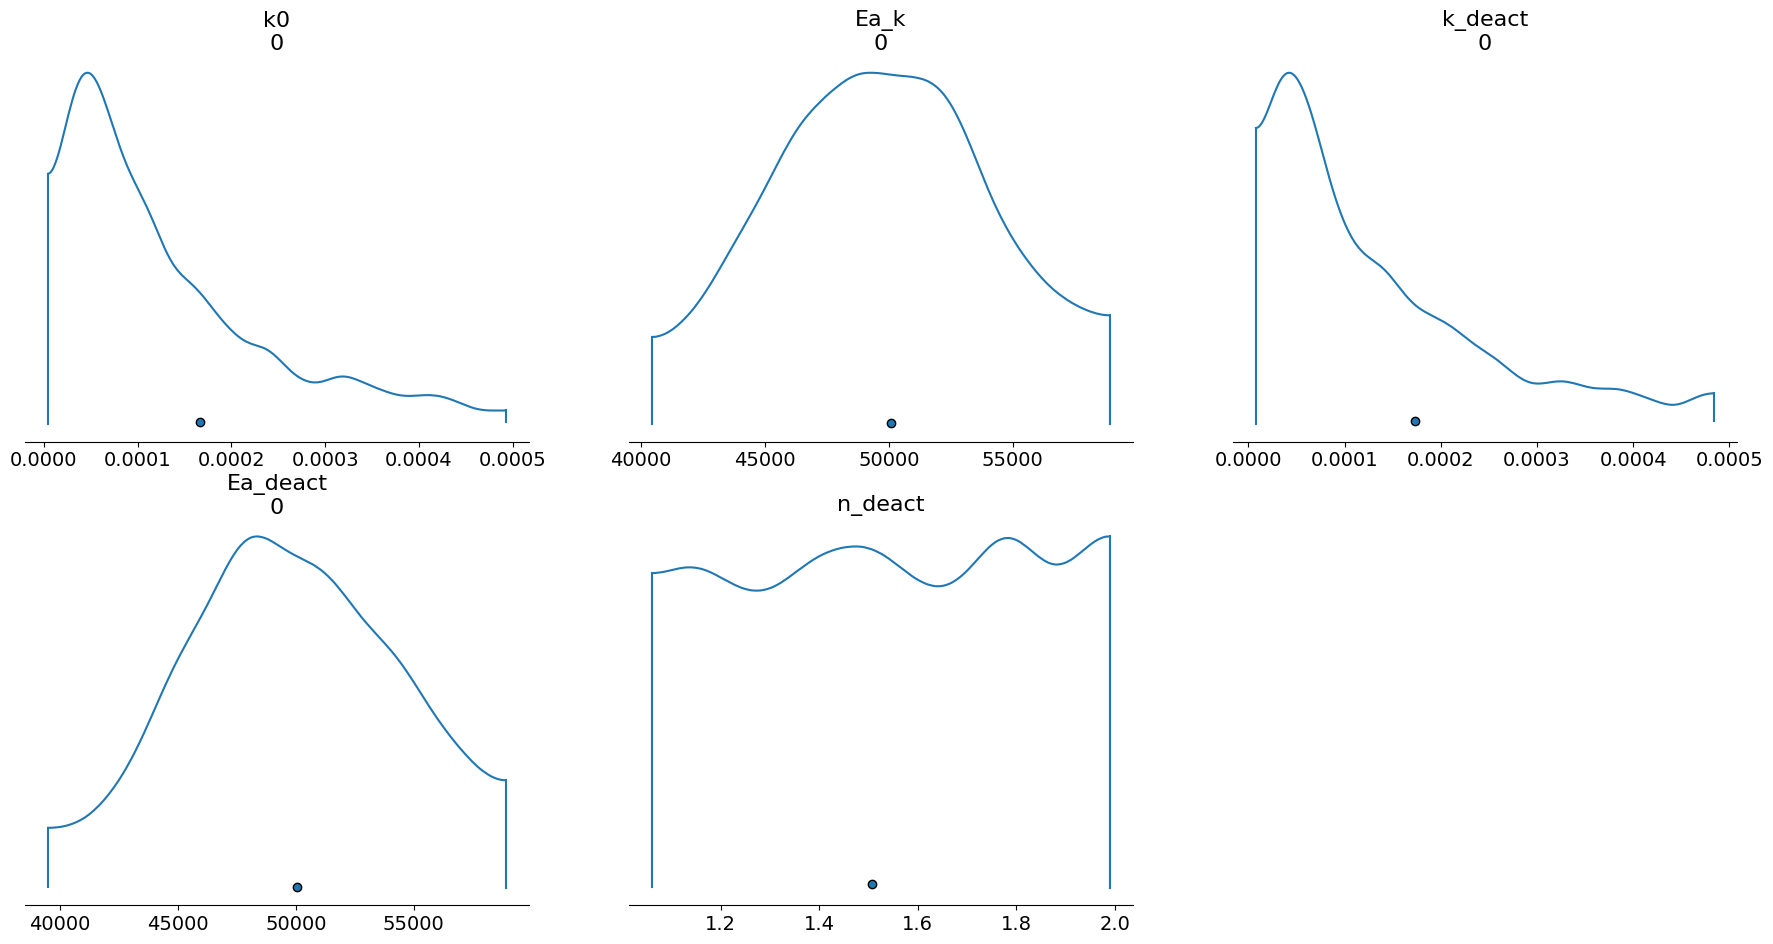

In [15]:
az.plot_density(
    prior_idata,
    group="prior",
    var_names=[
        "k0",
        "Ea_k",
        "k_deact",
        "Ea_deact",
        "n_deact",
    ]
)

In [16]:
r_prior = predict(prior_idata, T_obs, pi_obs, key="prior")
display(r_prior.shape)

(JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[1,25]>, JitTracer<float32[98,1]>)


(10, 98, 1, 25)

In [17]:
display(r_prior)

Array([[[[1.05022973e-05, 4.50008838e-06, 4.49657728e-06, ...,
          1.49724128e-05, 3.42119165e-06, 1.14504646e-05]],

        [[4.31921289e-05, 1.44505220e-05, 1.75743753e-05, ...,
          4.69574406e-05, 1.19656470e-05, 3.73950679e-05]],

        [[8.18476383e-06, 3.65551682e-06, 3.53435962e-06, ...,
          1.22106012e-05, 2.73961291e-06, 9.27519159e-06]],

        ...,

        [[7.56640075e-05, 2.38623343e-05, 3.04146633e-05, ...,
          7.71057385e-05, 2.01661187e-05, 6.20002465e-05]],

        [[2.05849592e-05, 7.87965564e-06, 8.61121316e-06, ...,
          2.59361859e-05, 6.22833841e-06, 2.02045758e-05]],

        [[5.40577776e-06, 2.58576574e-06, 2.36752885e-06, ...,
          8.69398446e-06, 1.89254479e-06, 6.53027837e-06]]],


       [[[1.05010113e-05, 4.49893287e-06, 4.49578329e-06, ...,
          1.49604775e-05, 3.42071144e-06, 1.14487966e-05]],

        [[4.31779117e-05, 1.44392961e-05, 1.75655987e-05, ...,
          4.68609760e-05, 1.19605738e-05, 3.73799376e

In [18]:
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt


@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_prior.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        jnp.arange(r_prior.shape[0]),
        jnp.quantile(r_prior[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_prior[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…

In [19]:
from numpyro.infer import MCMC, NUTS

seed = jax.random.PRNGKey(42)
kernel = NUTS(bayesian_model)
num_samples=4000
mcmc = MCMC(kernel, num_warmup=1000, num_samples=num_samples, num_chains=2)
mcmc.run(seed,T=T_obs, pi=pi_obs, r_obs=r_obs)
posterior_samples = mcmc.get_samples()
post_idata = az.from_numpyro(mcmc)


(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)
(JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[1]>, JitTracer<float32[98,1]>)


In [20]:
jax.local_device_count()

4

In [21]:
display(post_idata)

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'Ea_deact'}>],
       [<Axes: title={'center': 'n_deact'}>,
        <Axes: title={'center': 'n_deact'}>]], dtype=object)

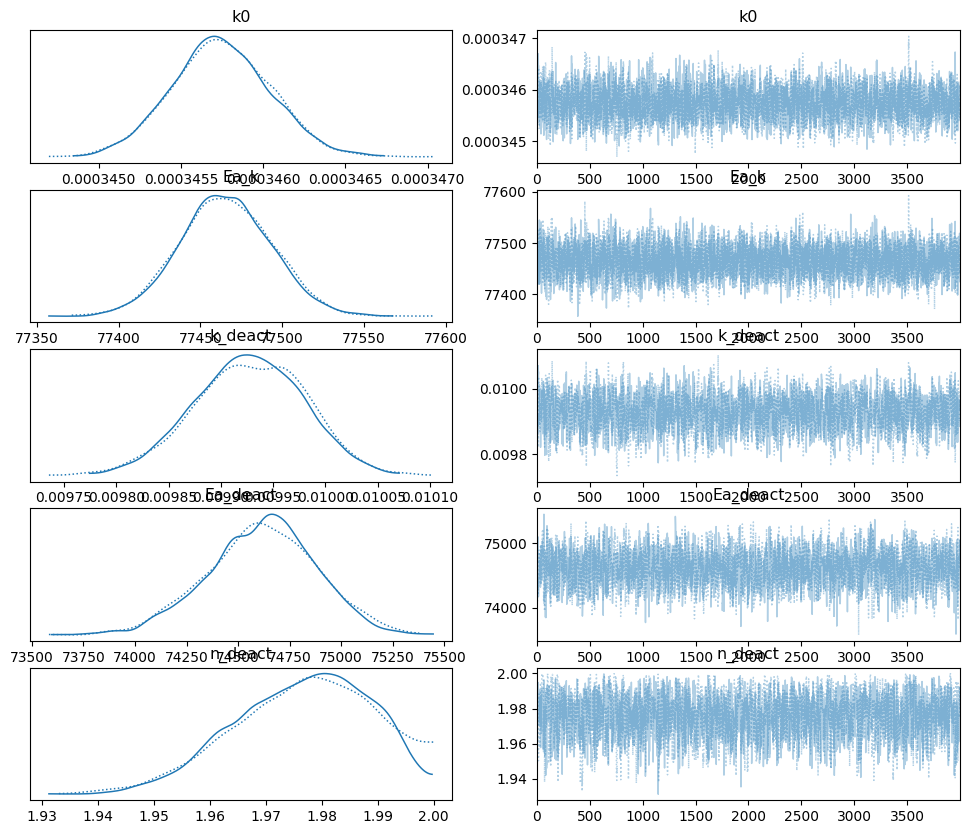

In [22]:
az.plot_trace(
    post_idata,
    divergences=False,
    var_names=[
        "k0",
        "Ea_k",
        "k_deact",
        "Ea_deact",
        "n_deact",
    ],
    )

In [23]:
r_post = predict(post_idata, T_obs, pi_obs, key="posterior")
display(r_post.shape)

(10, 98, 1, 25)

In [ ]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_post.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        jnp.arange(r_post.shape[0]),
        jnp.quantile(r_post[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_post[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…